# 04 - Forecast-window reliability and customer-count targets

All 534 study counties are evaluated hourly through 2023, without conditioning on storms. Windows are `(decision time, decision time + 6 or 12 hours]`; complete means 24 or 48 usable quarter-hour slots. Explicit zeros count as observations. Missing rows remain unknown.

In [1]:
import sys
from pathlib import Path
import hashlib
import json
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.plotting import BLUE, ORANGE, GREY, SEQ, use_style
use_style()
pd.set_option("display.max_columns", 12)

REBUILD = False  # True recomputes all training-period summaries; no holdout outage files are read.
summary_path = ROOT / "docs/checkpoint_1_observation_reliability.json"
folder = ROOT / "data/processed/eda/observation_reliability"
required = ["county_year", "state_month", "state_hour", "slot_distribution", "raw_county_year"]
if REBUILD or not summary_path.exists() or any(not (folder / f"{name}.parquet").exists() for name in required):
    subprocess.run([sys.executable, str(ROOT / "scripts/check_observation_reliability.py")], check=True, cwd=ROOT)
metadata = json.loads(summary_path.read_text(encoding="utf-8"))
if not metadata.get("code_files"):
    raise ValueError("Observation code fingerprints are missing: rerun with REBUILD=True")
for item in metadata["files"] + metadata["code_files"]:
    assert hashlib.sha256((ROOT / item["path"]).read_bytes()).hexdigest() == item["sha256"], "Source changed: rerun with REBUILD=True"
county_year, state_month, state_hour, slot_distribution, raw_county_year = [
    pd.read_parquet(folder / f"{name}.parquet") for name in required]
totals = pd.DataFrame(metadata["totals"]).set_index("horizon")
yearly = pd.DataFrame(metadata["by_year"])
states = pd.DataFrame(metadata["by_state"])
print("Training years:", metadata["training_years"])
print("Observation envelope:", metadata["envelope_start"], "to", metadata["envelope_end_exclusive"], "(exclusive)")
print("No classification targets or models are computed in this checkpoint.")

Training years: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Observation envelope: 2014-11-01 04:00:00 to 2024-01-01 00:00:00 (exclusive)
No classification targets or models are computed in this checkpoint.


## Boundary exclusions and observation status

The calendar-year frame includes the unobserved start of 2014. Origins before the first file timestamp and windows extending beyond the training cutoff are excluded from rate denominators. Missing county readings and internal file gaps remain in the denominator.

,origins,boundary_excluded,in_bounds,unknown,partial,complete,complete_unflagged
horizon,,,,,,,
6,46804032,3901404,42902628,23574322,16022113,3306193,3305052
12,46804032,3904608,42899424,18217361,22646978,2035085,2033754


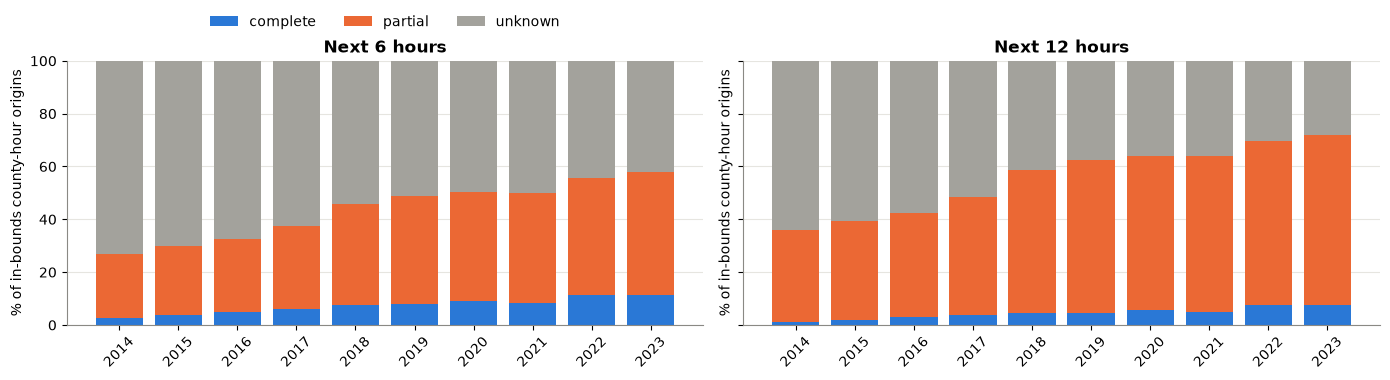

In [2]:
display(totals[["origins", "boundary_excluded", "in_bounds", "unknown", "partial", "complete", "complete_unflagged"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, horizon in zip(axes, [6, 12]):
    data = yearly[yearly.horizon.eq(horizon)].set_index("year")
    bottom = np.zeros(len(data))
    for status, color in [("complete", BLUE), ("partial", ORANGE), ("unknown", GREY)]:
        pct = data[status] / data.in_bounds * 100
        ax.bar(data.index.astype(str), pct, bottom=bottom, color=color, label=status)
        bottom += pct
    ax.set(title=f"Next {horizon} hours", ylabel="% of in-bounds county-hour origins", ylim=(0, 100))
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.22))
plt.tight_layout()
plt.show()

## Retention under stricter rules

The 50% and 90% thresholds are diagnostic comparisons, not approved eligibility rules. Complete windows can still contain erroneous measurements. The unflagged subset additionally excludes off-grid records, duplicate slots, invalid counts and counts above the provisional housing-based customer estimate.

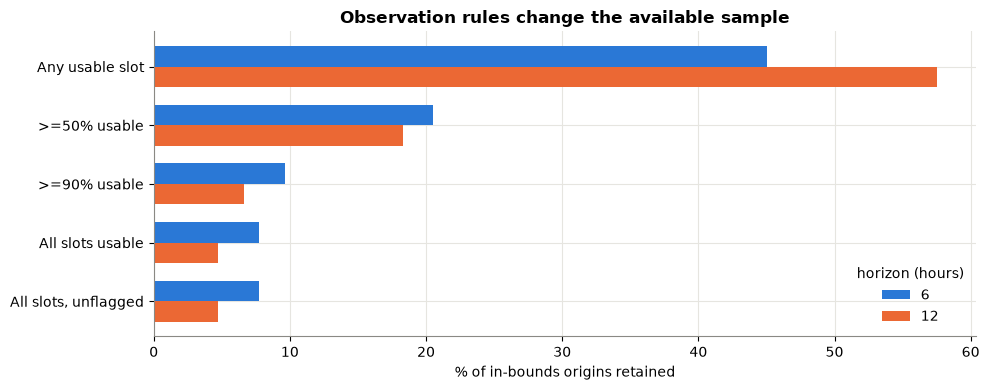

horizon,6,12
rule,,
any_observed,19328306,24682063
at_least_half,8803094,7862947
at_least_90pct,4125689,2855415
complete,3306193,2035085
complete_unflagged,3305052,2033754


In [3]:
rules = ["any_observed", "at_least_half", "at_least_90pct", "complete", "complete_unflagged"]
labels = ["Any usable slot", ">=50% usable", ">=90% usable", "All slots usable", "All slots, unflagged"]
retention = totals[rules].div(totals.in_bounds, axis=0).T * 100
retention.index = labels
ax = retention.plot.barh(figsize=(10, 4), color=[BLUE, ORANGE], width=.7)
ax.invert_yaxis()
ax.set(xlabel="% of in-bounds origins retained", ylabel="", title="Observation rules change the available sample")
ax.legend(title="horizon (hours)", frameon=False)
plt.tight_layout()
plt.show()
display(totals[rules].T.rename_axis("rule"))

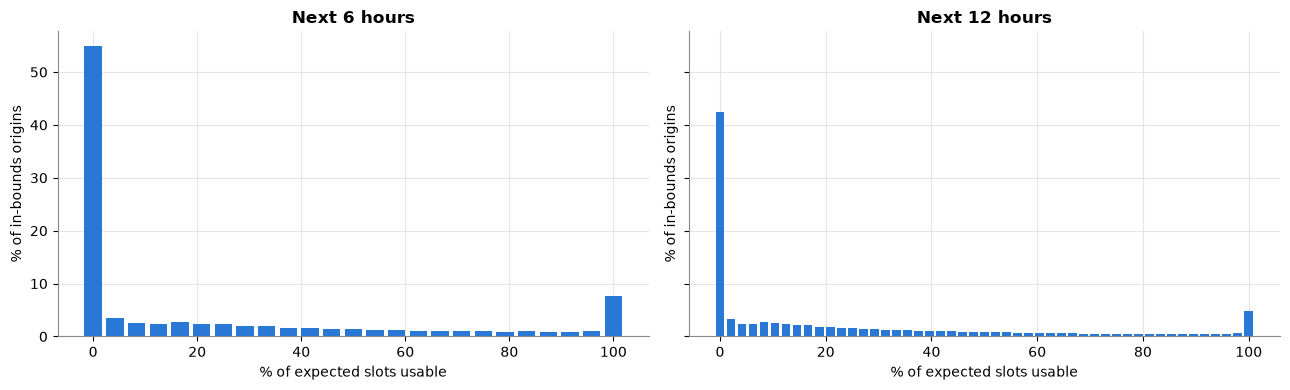

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, horizon in zip(axes, [6, 12]):
    counts = slot_distribution[slot_distribution.horizon.eq(horizon)].groupby("usable_slots").windows.sum()
    ax.bar(counts.index / (horizon * 4) * 100, counts / counts.sum() * 100,
           width=80 / (horizon * 4), color=BLUE)
    ax.set(title=f"Next {horizon} hours", xlabel="% of expected slots usable", ylabel="% of in-bounds origins")
plt.tight_layout()
plt.show()

## Geographic and county-size selection

Retention is measured against the same hourly schedule for every county. Housing quartiles are calculated within each year and describe sample composition; they are not forecasting features. Counties with no records must remain unknown.

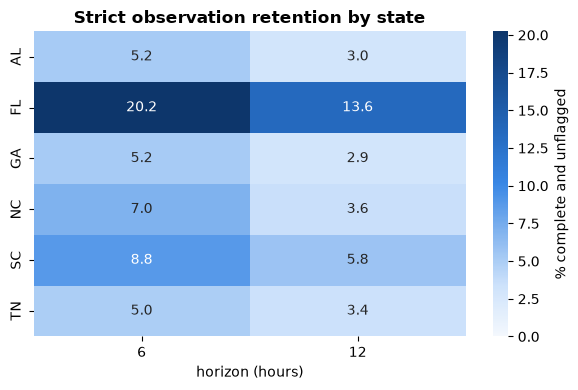

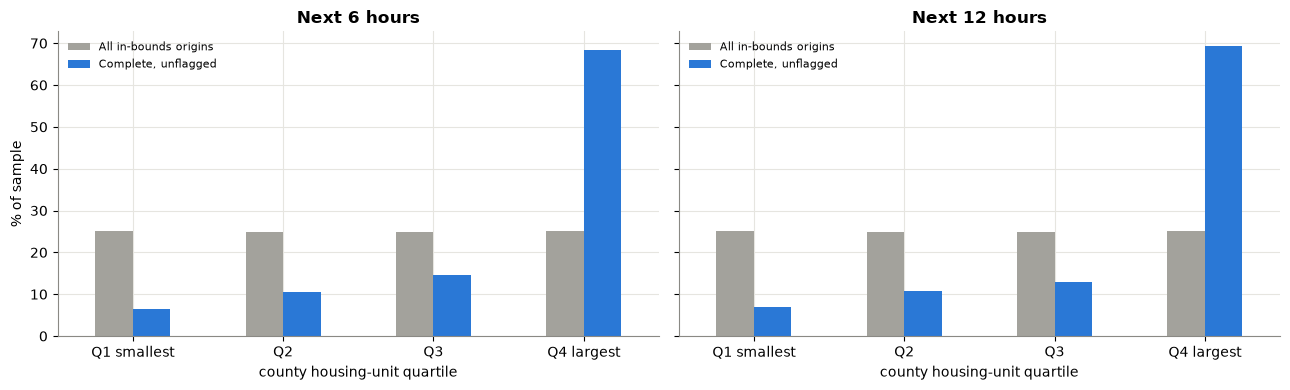

In [5]:
state_rates = states.assign(retention=100 * states.complete_unflagged / states.in_bounds)
state_grid = state_rates.pivot(index="state", columns="horizon", values="retention")
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(state_grid, annot=True, fmt=".1f", cmap=SEQ, vmin=0, ax=ax,
            cbar_kws={"label": "% complete and unflagged"})
ax.set(title="Strict observation retention by state", xlabel="horizon (hours)", ylabel="")
ax.grid(False)
plt.tight_layout()
plt.show()
quartiles = pd.DataFrame(metadata["by_housing_quartile"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, horizon in zip(axes, [6, 12]):
    data = quartiles[quartiles.horizon.eq(horizon)].set_index("housing_quartile")
    shares = pd.DataFrame({"All in-bounds origins": data.in_bounds / data.in_bounds.sum(),
                          "Complete, unflagged": data.complete_unflagged / data.complete_unflagged.sum()}) * 100
    shares.plot.bar(ax=ax, color=[GREY, BLUE], rot=0)
    ax.set(title=f"Next {horizon} hours", xlabel="county housing-unit quartile", ylabel="% of sample")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

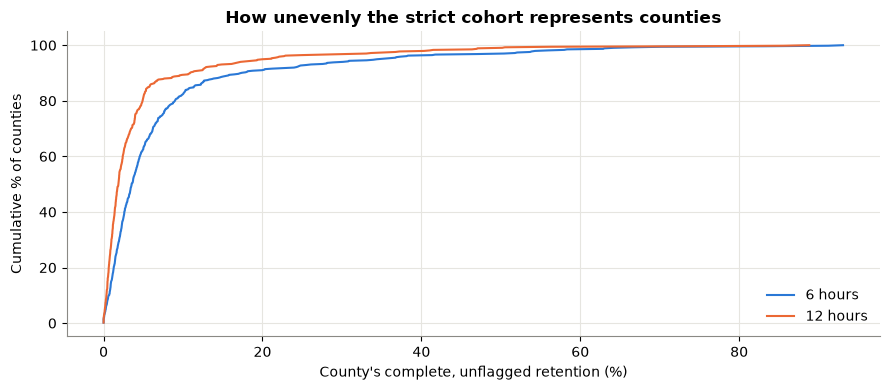

Counties with no stored training-period readings:


,county_name
fips_code,
47005,"Benton County, Tennessee"
47039,"Decatur County, Tennessee"
47071,"Hardin County, Tennessee"
47085,"Humphreys County, Tennessee"
47091,"Johnson County, Tennessee"
47135,"Perry County, Tennessee"


County retention extremes (6-hour windows):


,county_name,in_bounds,complete_unflagged,retention_pct
32,"Colbert County, Alabama",80342,0,0.000000
882,"Benton County, Tennessee",80342,0,0.000000
916,"Decatur County, Tennessee",80342,0,0.000000
948,"Hardin County, Tennessee",80342,0,0.000000
962,"Humphreys County, Tennessee",80342,0,0.000000
964,"Jackson County, Tennessee",80342,0,0.000000
968,"Johnson County, Tennessee",80342,0,0.000000
1012,"Perry County, Tennessee",80342,0,0.000000
236,"Pinellas County, Florida",80342,50534,62.898608
142,"Brevard County, Florida",80342,50623,63.009385


In [6]:
county_totals = county_year.groupby(["fips_code", "county_name", "horizon"], as_index=False)[
    ["in_bounds", "any_observed", "complete", "complete_unflagged"]].sum()
county_totals["retention_pct"] = 100 * county_totals.complete_unflagged / county_totals.in_bounds
fig, ax = plt.subplots(figsize=(9, 4))
for horizon, color in [(6, BLUE), (12, ORANGE)]:
    values = np.sort(county_totals.loc[county_totals.horizon.eq(horizon), "retention_pct"])
    ax.plot(values, np.arange(1, len(values) + 1) / len(values) * 100, label=f"{horizon} hours", color=color)
ax.set(xlabel="County's complete, unflagged retention (%)", ylabel="Cumulative % of counties",
       title="How unevenly the strict cohort represents counties")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
county_lookup = county_year.drop_duplicates("fips_code").set_index("fips_code").county_name
print("Counties with no stored training-period readings:")
display(county_lookup.reindex(metadata["counties_never_stored"]).to_frame())
print("County retention extremes (6-hour windows):")
county6 = county_totals[county_totals.horizon.eq(6)].sort_values(["retention_pct", "fips_code"])
display(pd.concat([county6.head(8), county6.tail(8)])[["county_name", "in_bounds", "complete_unflagged", "retention_pct"]])

## Seasonal and time-of-day selection

Each rate uses eligible origins in that month or UTC hour. Differences describe the observation process as well as weather and outage activity; they are not estimates of outage risk.

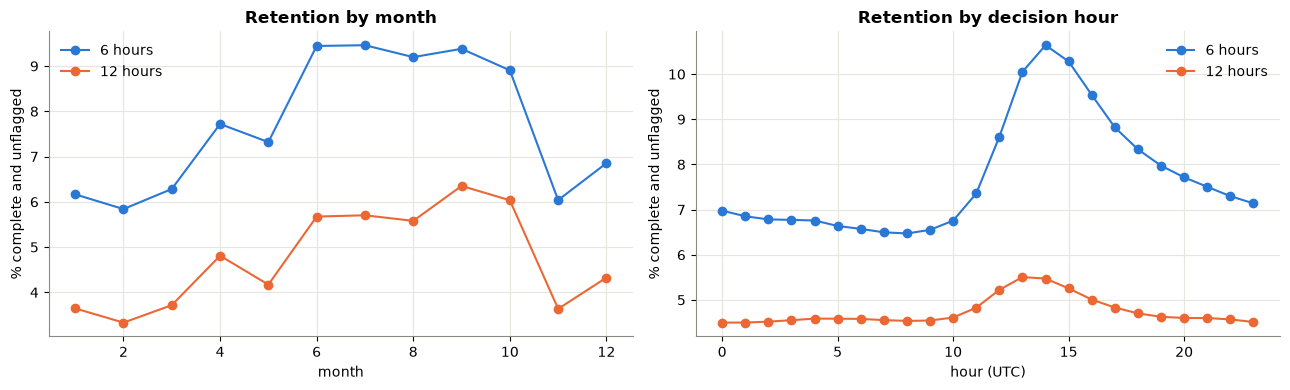

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for horizon, color in [(6, BLUE), (12, ORANGE)]:
    for ax, data, dimension in [(axes[0], state_month, "month"), (axes[1], state_hour, "hour")]:
        grouped = data[data.horizon.eq(horizon)].groupby(dimension)[["complete_unflagged", "in_bounds"]].sum()
        ax.plot(grouped.index, 100 * grouped.complete_unflagged / grouped.in_bounds,
                marker="o", color=color, label=f"{horizon} hours")
        ax.set(xlabel=dimension + (" (UTC)" if dimension == "hour" else ""), ylabel="% complete and unflagged")
        ax.legend(frameon=False)
axes[0].set_title("Retention by month")
axes[1].set_title("Retention by decision hour")
plt.tight_layout()
plt.show()

## Raw reading flags

These counts use each original reading once, unlike overlapping window summaries. Above-proxy counts are suspicious, not proven errors; no values are capped or imputed. Null cells, absent records and explicit zeros remain distinct.

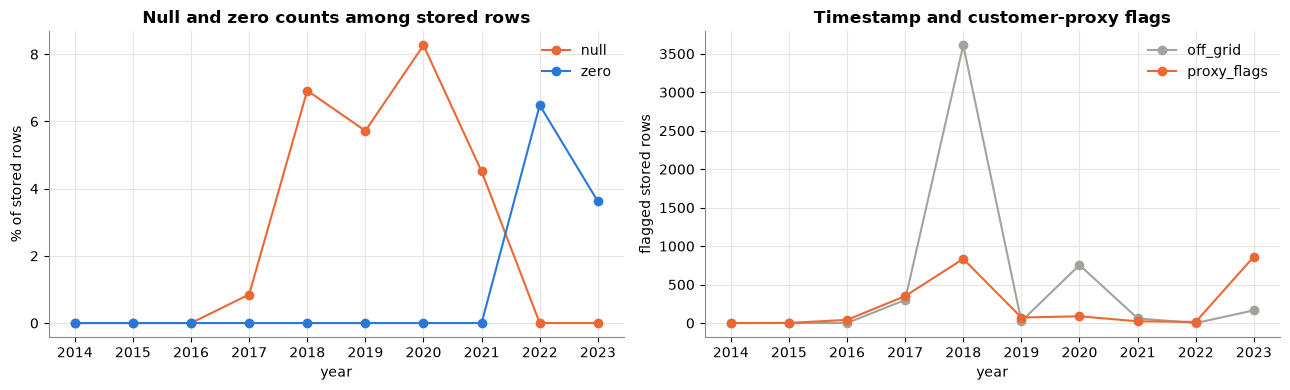

,rows,null,zero,off_grid,duplicate_rows,invalid,proxy_flags
year,,,,,,,
2014,358659,0,0,0,0,0,0
2015,2580145,0,0,0,0,0,2
2016,2960707,0,0,0,0,0,41
2017,3388524,28781,0,300,0,0,350
2018,4553450,315048,0,3611,0,0,834
2019,4808385,275065,0,23,0,0,72
2020,5194354,429447,0,754,0,0,88
2021,4832707,218042,0,61,0,0,23
2022,5289340,0,342871,0,0,0,15


Reconciliation checks passed. Checkpoint 1 reconciliation complete.


In [8]:
raw_year = raw_county_year.groupby("year")[["rows", "null", "zero", "off_grid", "duplicate_rows", "invalid", "proxy_flags"]].sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for field, color in [("null", ORANGE), ("zero", BLUE)]:
    axes[0].plot(raw_year.index, 100 * raw_year[field] / raw_year.rows, marker="o", label=field, color=color)
axes[0].set(title="Null and zero counts among stored rows", ylabel="% of stored rows", xlabel="year")
for field, color in [("off_grid", GREY), ("proxy_flags", ORANGE)]:
    axes[1].plot(raw_year.index, raw_year[field], marker="o", label=field, color=color)
axes[1].set(title="Timestamp and customer-proxy flags", ylabel="flagged stored rows", xlabel="year")
for ax in axes:
    ax.legend(frameon=False)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
display(raw_year)
assert (county_year.unknown + county_year.partial + county_year.complete == county_year.in_bounds).all()
assert (county_year.complete_unflagged <= county_year.complete).all()
assert (county_year.usable_window_slots <= county_year.expected_slots).all()
print("Reconciliation checks passed. Checkpoint 1 reconciliation complete.")

## Customer-count targets

Primary severity is the uncapped recorded peak on the exact quarter-hour grid; major means **strictly more than 5,000 customers**. Off-grid readings flag a window and are excluded from the peak. These charts use complete, unflagged windows unless stated otherwise. Rates describe this selected cohort, not all county decisions; overlapping windows are not independent events.

horizon,6,12
in_bounds,42902628,42899424
strict,3305052,2033754
strict_positive,71248,82340
strict_negative,3233804,1951414
partial_positive_unflagged,17900,47060
partial_positive_flagged,428,962
partial_uncertain,16003785,22598956
unknown,23574322,18217361


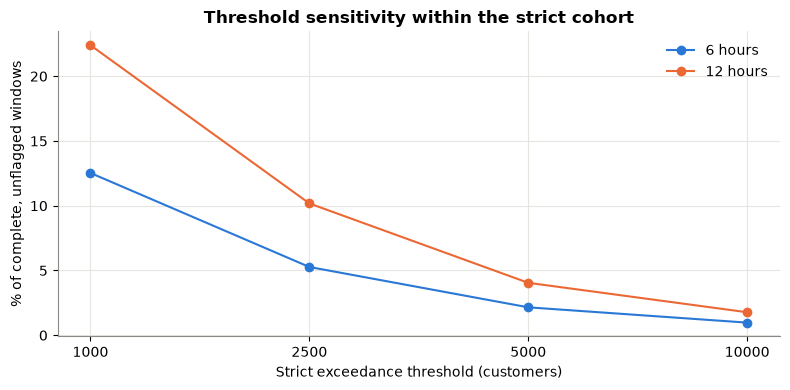

,n,mean,0,0.25,0.5,0.75,0.9,0.95,0.99,1
horizon,,,,,,,,,,
6,3305052,818.245237,0.0,9.0,56.0,277.0,1359.0,2610.0,9798.00,898340.0
12,2033754,1407.454527,0.0,19.0,140.0,803.0,2537.0,4227.0,16855.47,898340.0


In [9]:
target_path = ROOT / "docs/checkpoint_2_customer_targets.json"
target_folder = ROOT / "data/processed/eda/customer_targets"
if REBUILD or not target_path.exists() or any(not (target_folder / f"{name}.parquet").exists() for name in ["county_year", "state_season"]):
    subprocess.run([sys.executable, str(ROOT / "scripts/check_customer_targets.py")], check=True, cwd=ROOT)
target_meta = json.loads(target_path.read_text(encoding="utf-8"))
for item in target_meta["files"] + target_meta["code_files"]:
    assert hashlib.sha256((ROOT / item["path"]).read_bytes()).hexdigest() == item["sha256"], item["path"]
target_totals = pd.DataFrame(target_meta["totals"])
target_counties = pd.read_parquet(target_folder / "county_year.parquet")
primary = target_totals[target_totals.threshold.eq(5000)].set_index("horizon")
def show_target_figure():
    plt.tight_layout()
    plt.show()
display(primary[["in_bounds", "strict", "strict_positive", "strict_negative", "partial_positive_unflagged", "partial_positive_flagged", "partial_uncertain", "unknown"]].T)
fig, ax = plt.subplots(figsize=(8, 4))
for h, color in [(6, BLUE), (12, ORANGE)]:
    data = target_totals[target_totals.horizon.eq(h)]
    ax.plot(data.threshold.astype(str), 100 * data.strict_positive / data.strict, marker="o", color=color, label=f"{h} hours")
ax.set(xlabel="Strict exceedance threshold (customers)", ylabel="% of complete, unflagged windows", title="Threshold sensitivity within the strict cohort")
ax.legend(frameon=False)
show_target_figure()
display(pd.DataFrame(target_meta["strict_peak_quantiles"]).set_index("horizon"))

## Peak definition sensitivity

Hourly medians use `(hour, hour + 1 hour]`, then take the maximum over the horizon. Medians can suppress brief high readings. Removing above-proxy readings is a separate diagnostic, not a correction: a resulting incomplete window below the threshold remains uncertain. The proxy comparison includes flagged complete windows so its effect can be measured.

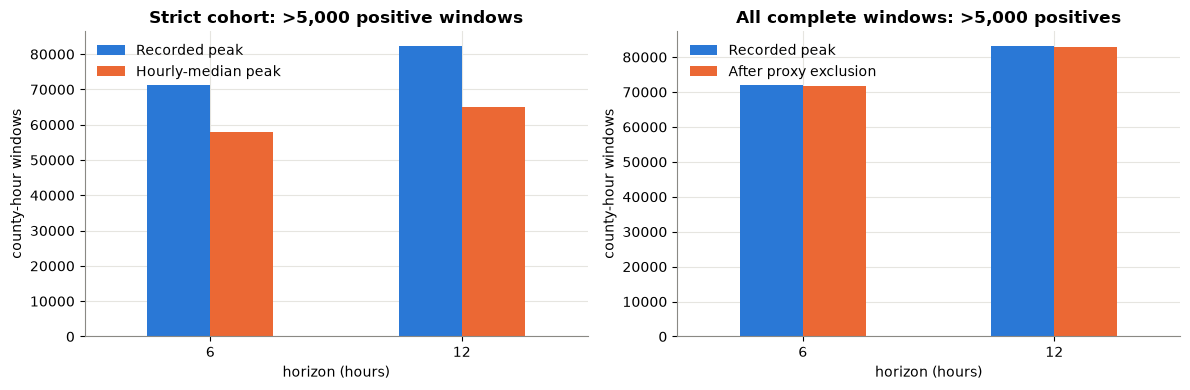

,horizon,threshold,median_lost_positive_strict,proxy_lost_positive_complete,proxy_uncertain_complete
0,6,1000,124267,349,349
1,6,2500,55755,295,381
2,6,5000,13281,249,585
3,6,10000,3640,173,727
4,12,1000,135102,246,246
5,12,2500,72205,208,293
6,12,5000,17344,226,610
7,12,10000,4746,163,804


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison = pd.DataFrame({"Recorded peak": primary.strict_positive, "Hourly-median peak": primary.median_positive_strict})
comparison.plot.bar(ax=axes[0], color=[BLUE, ORANGE], rot=0)
axes[0].set(title="Strict cohort: >5,000 positive windows", xlabel="horizon (hours)", ylabel="county-hour windows")
comparison2 = pd.DataFrame({"Recorded peak": primary.complete_positive, "After proxy exclusion": primary.proxy_excluded_positive_complete})
comparison2.plot.bar(ax=axes[1], color=[BLUE, ORANGE], rot=0)
axes[1].set(title="All complete windows: >5,000 positives", xlabel="horizon (hours)", ylabel="county-hour windows")
for ax in axes:
    ax.legend(frameon=False)
show_target_figure()
display(target_totals[["horizon", "threshold", "median_lost_positive_strict", "proxy_lost_positive_complete", "proxy_uncertain_complete"]])

## Geography, year, season and county size

Each panel divides major windows by complete, unflagged windows in that group. Housing quartiles are recalculated within each year; seasons use the UTC decision month. Observation selection and repeated hours of sustained outages affect these rates. They do not establish causes or forecast performance.

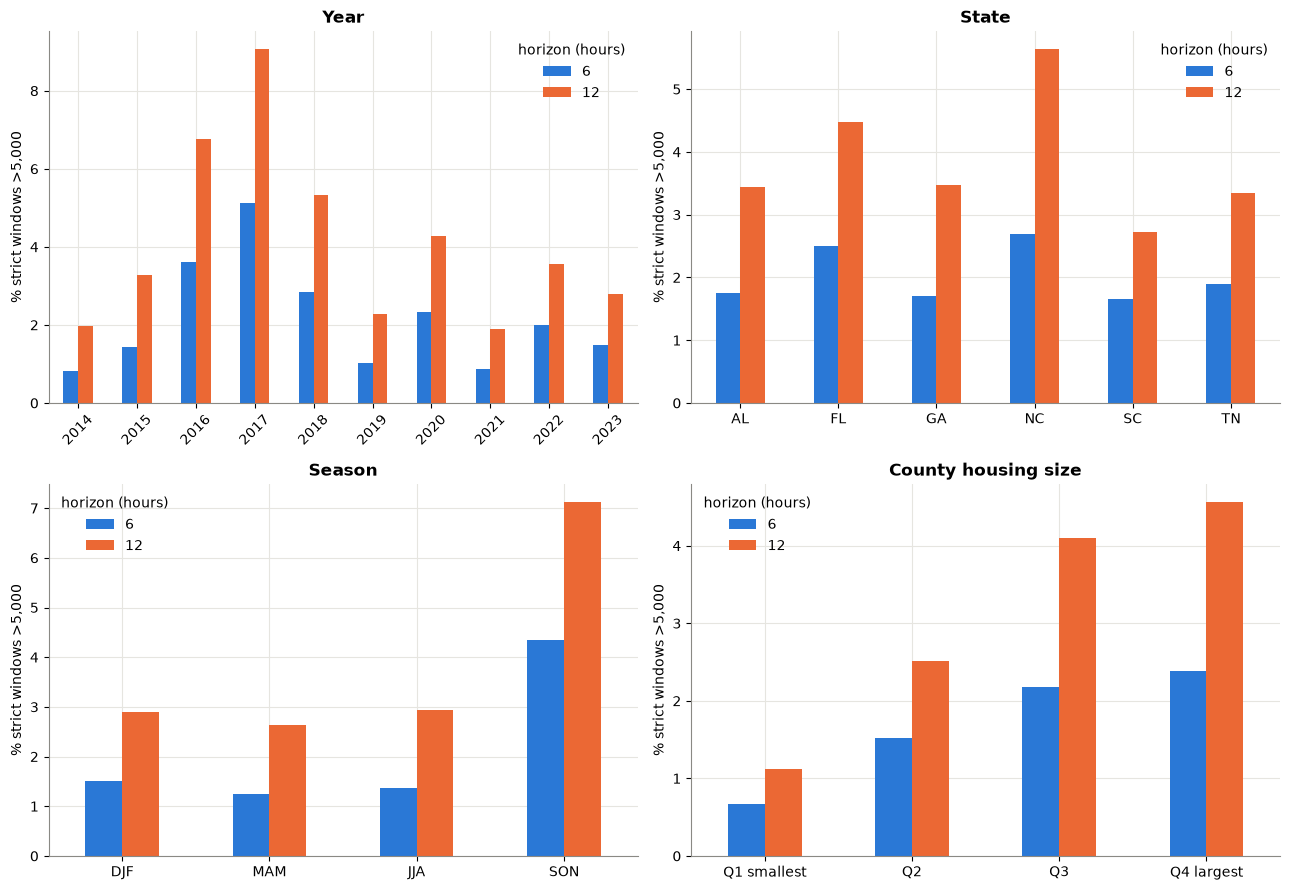

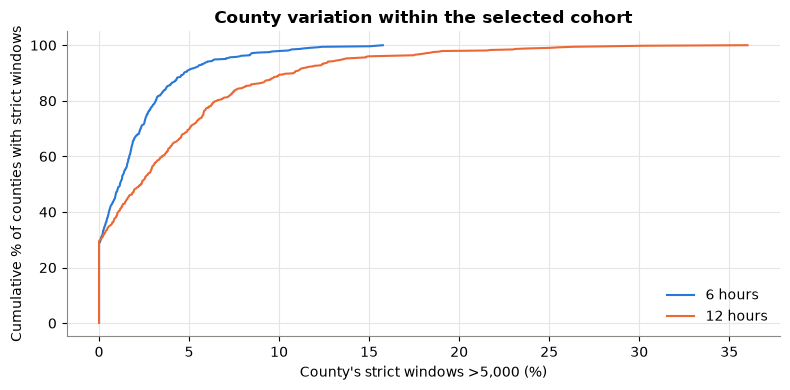

,fips_code,county_name,state,horizon,strict,strict_positive,major_pct
1034,47157,"Shelby County, Tennessee",TN,6,51586,3045,5.902764
218,12086,"Miami-Dade County, Florida",FL,6,74775,2224,2.974256
704,37119,"Mecklenburg County, North Carolina",NC,6,53604,1721,3.210581
144,12011,"Broward County, Florida",FL,6,73284,1632,2.226953
232,12099,"Palm Beach County, Florida",FL,6,66941,1543,2.305015
202,12071,"Lee County, Florida",FL,6,44920,1531,3.408281
386,13121,"Fulton County, Georgia",GA,6,56433,1423,2.521574
188,12057,"Hillsborough County, Florida",FL,6,41603,1344,3.230536
236,12103,"Pinellas County, Florida",FL,6,50534,1296,2.564610
914,47037,"Davidson County, Tennessee",TN,6,46856,1193,2.546099


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, key, dimension, title in [
    (axes[0, 0], "by_year", "year", "Year"),
    (axes[0, 1], "by_state", "state", "State"),
    (axes[1, 0], "by_season", "season", "Season"),
    (axes[1, 1], "by_housing_quartile", "housing_quartile", "County housing size")]:
    data = pd.DataFrame(target_meta[key])
    data = data[data.threshold.eq(5000)].copy()
    data["rate"] = 100 * data.strict_positive / data.strict
    grid = data.pivot(index=dimension, columns="horizon", values="rate")
    if dimension == "season":
        grid = grid.reindex(["DJF", "MAM", "JJA", "SON"])
    grid.plot.bar(ax=ax, color=[BLUE, ORANGE], rot=45 if dimension == "year" else 0)
    ax.set(title=title, xlabel="", ylabel="% strict windows >5,000")
    ax.legend(title="horizon (hours)", frameon=False)
show_target_figure()
county_target_totals = target_counties[target_counties.threshold.eq(5000)].groupby(["fips_code", "county_name", "state", "horizon"])[["strict", "strict_positive"]].sum().reset_index()
county_target_totals["major_pct"] = 100 * county_target_totals.strict_positive / county_target_totals.strict.replace(0, np.nan)
fig, ax = plt.subplots(figsize=(8, 4))
for h, color in [(6, BLUE), (12, ORANGE)]:
    values = np.sort(county_target_totals.loc[county_target_totals.horizon.eq(h), "major_pct"].dropna())
    ax.plot(values, np.arange(1, len(values) + 1) / len(values) * 100, color=color, label=f"{h} hours")
ax.set(xlabel="County's strict windows >5,000 (%)", ylabel="Cumulative % of counties with strict windows", title="County variation within the selected cohort")
ax.legend(frameon=False)
show_target_figure()
display(county_target_totals[county_target_totals.horizon.eq(6)].sort_values("strict_positive", ascending=False).head(12))

## Cohort proposed for review

Use complete, unflagged windows for the primary comparison, retaining both peak count and the >5,000 label. Keep partial-window exceedances as separate positive evidence; partial windows below the threshold and wholly unobserved windows remain uncertain. Future completeness and anomaly flags must not enter forecast features. This cohort supports a selected-cohort baseline, with limited coverage; it does not resolve performance across all county preparation decisions.

In [12]:
for h in [6, 12]:
    row = primary.loc[h]
    assert row.strict == totals.loc[h, "complete_unflagged"]
    assert row.strict_positive + row.strict_negative == row.strict
assert (target_totals.median_positive_strict <= target_totals.strict_positive).all()
assert (target_totals.proxy_excluded_positive_complete <= target_totals.complete_positive).all()
print("Checkpoint 2 reconciled. Checkpoint 2 reconciliation complete.")

Checkpoint 2 reconciled. Checkpoint 2 reconciliation complete.


## Geography integrity and exclusions

This audit checks 2014-2025 storm geography only, without reading holdout outage outcomes. Unmatched zones remain unresolved. The 119 supported Georgia corrections are all in 2025: 59 invalid IDs plus 60 valid IDs assigned to the wrong named county. The derived overlay preserves originals; it does not establish historical zone boundaries or alter county-hour targets.

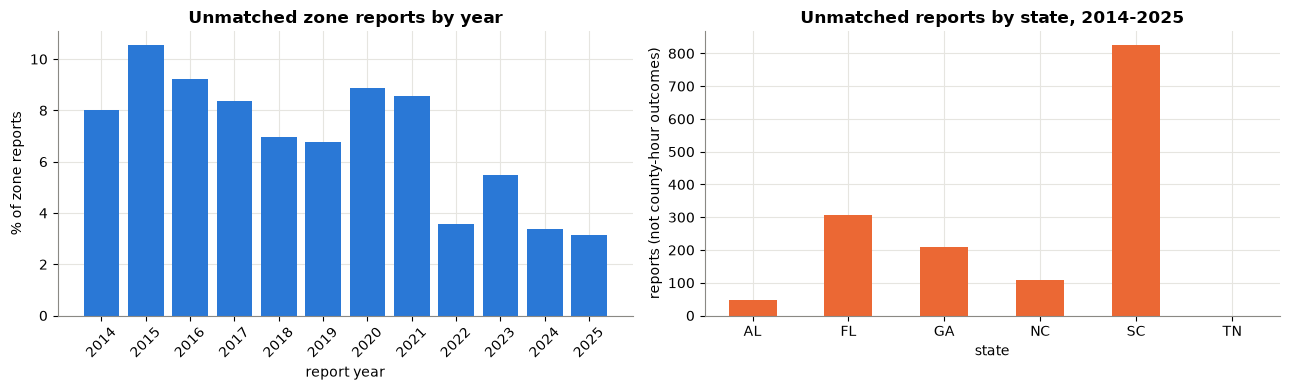

,year,reports,zone_reports,unmatched,name_conflicts
0,2014,6721,1759,141,0
1,2015,7329,1639,173,0
2,2016,8066,2580,238,0
3,2017,7675,1701,142,0
4,2018,7463,2208,154,0
5,2019,6647,1244,84,0
6,2020,7855,1228,109,0
7,2021,5607,1135,97,0
8,2022,7709,2257,81,0
9,2023,10662,2187,120,0


,event_id,original_cz_name,original_fips,original_fips_valid,corrected_fips
0,1236639,HARALSON,13041,False,13143
1,1236641,PAULDING,13031,True,13223
2,1237165,FORSYTH,13022,False,13117
3,1237178,GWINNETT,13034,False,13135
4,1241545,CRAWFORD,13081,True,13079
5,1241547,BIBB,13082,False,13021
6,1244271,LAMAR,13070,False,13171
7,1244273,BUTTS,13058,False,13035
8,1237181,CLAYTON,13055,True,13063
9,1237183,HENRY,13057,True,13151


,year,horizon,excluded_origins_per_county,excluded_county_origins
0,2023,6,6,3204
1,2023,12,12,6408
2,2024,6,6,3204
3,2024,12,12,6408
4,2025,6,6,3204
5,2025,12,12,6408


In [13]:
geo_path = ROOT / "docs/checkpoint_3_geography_audit.json"
geo_folder = ROOT / "data/processed/eda/geography_criteria"
if REBUILD or not geo_path.exists() or any(not (geo_folder / f"{name}.parquet").exists() for name in ["mapping_overlay", "audited_event_counties", "unmatched_events"]):
    subprocess.run([sys.executable, str(ROOT / "scripts/check_geography_criteria.py")], check=True, cwd=ROOT)
geo_meta = json.loads(geo_path.read_text(encoding="utf-8"))
for item in geo_meta["files"] + geo_meta["code_files"]:
    assert hashlib.sha256((ROOT / item["path"]).read_bytes()).hexdigest() == item["sha256"], item["path"]
geo_year = pd.DataFrame(geo_meta["by_year"])
geo_losses = pd.DataFrame(geo_meta["exclusions_by_year_state_type"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(geo_year.year.astype(str), 100 * geo_year.unmatched / geo_year.zone_reports, color=BLUE)
axes[0].set(title="Unmatched zone reports by year", ylabel="% of zone reports", xlabel="report year")
axes[0].tick_params(axis="x", rotation=45)
state_losses = geo_losses.groupby("state_abbr").unmatched.sum()
state_losses.plot.bar(ax=axes[1], color=ORANGE, rot=0)
axes[1].set(title="Unmatched reports by state, 2014-2025", xlabel="state", ylabel="reports (not county-hour outcomes)")
plt.tight_layout()
plt.show()
display(geo_year)
overlay = pd.read_parquet(geo_folder / "mapping_overlay.parquet")
display(overlay[["event_id", "original_cz_name", "original_fips", "original_fips_valid", "corrected_fips"]].head(12))
assert len(overlay) == geo_meta["totals"]["supported_corrections"]
display(pd.DataFrame(geo_meta["split_boundary_exclusions"]))

## Forecast criteria for review

Use [the feature-availability matrix](../docs/feature_availability.md) and [modeling criteria](../docs/modeling_criteria.md) before building predictors. Future completeness and realized storm reports are not advance inputs. Splits are chronological, with future outcome windows purged at boundaries. Recall must be reported with precision, false alerts and coverage; no numeric operational acceptance threshold has been approved. See the [handoff](../docs/teammate_handoff.md) for reproduction commands and next steps.